Total number of processing samples: 769
Proportion data saved to: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Global_Fragment_analysis/Result/fragment_size_proportions.csv


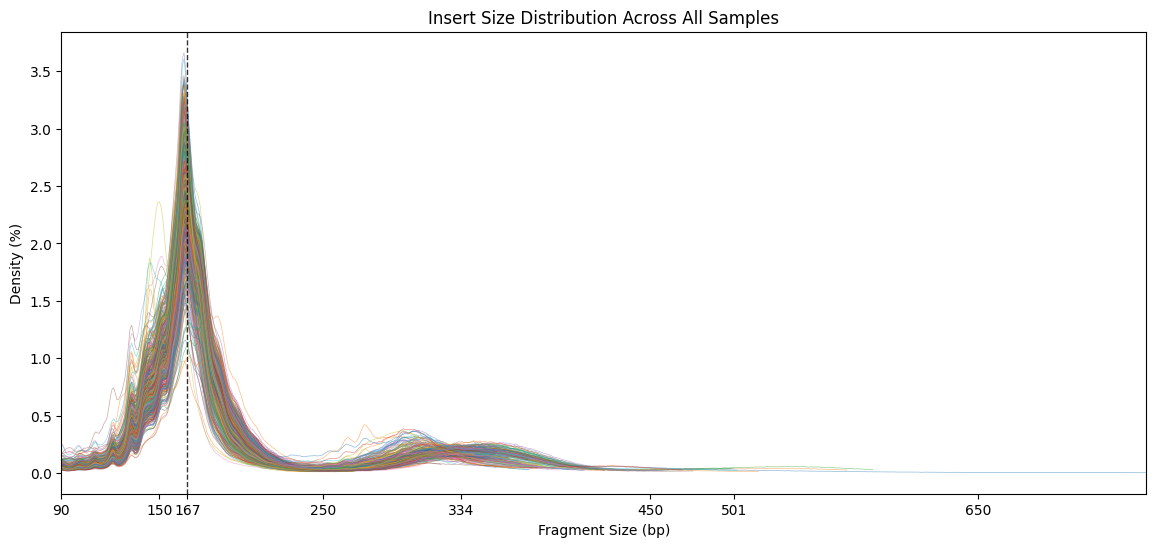

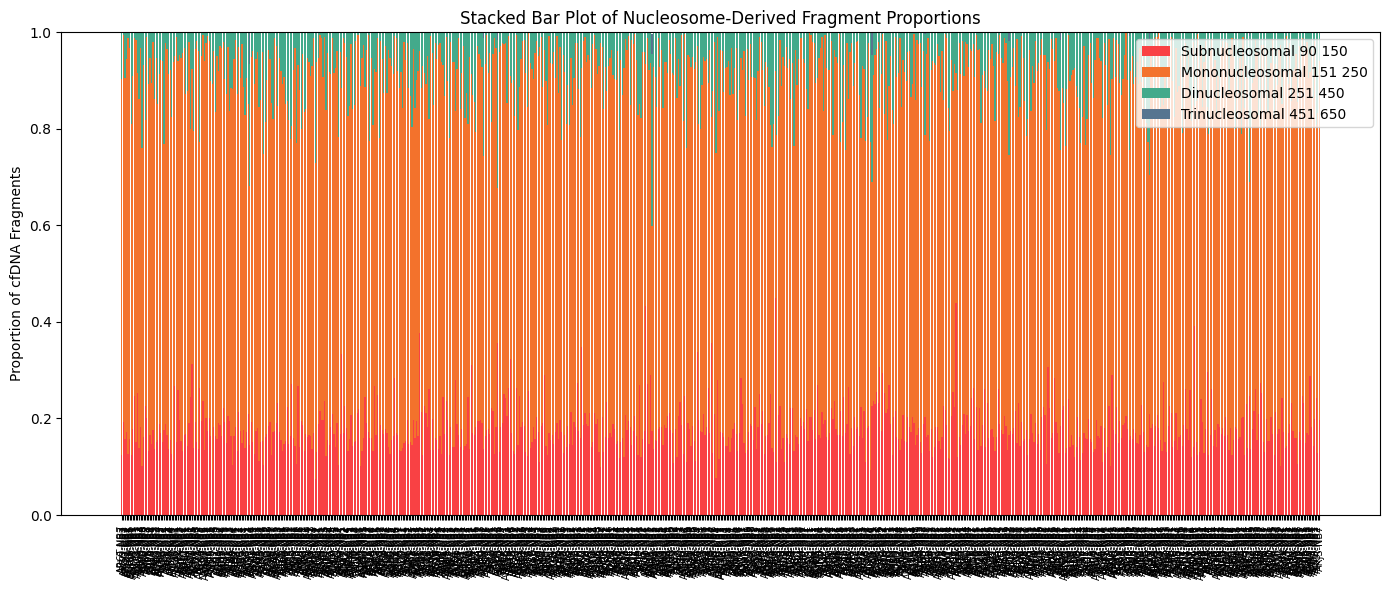

Density and stacked bar plots saved successfully.


In [2]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import io

# ================================
# CONFIGURATION
# ================================

directory = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Global_Fragment_analysis/Result"
output_directory = directory 

# ================================
# FILE LOADING
# ================================

file_paths = glob.glob(os.path.join(directory, "*.metrics.txt"))
samplenames = [os.path.basename(x).replace(".metrics.txt", "") for x in file_paths]

# Initialize main DataFrame and proportions storage
all_data = pd.DataFrame()
fragment_proportions = {}

# ================================
# PROCESS EACH FILE
# ================================
total_files = len(file_paths)
print(f"Total number of processing samples: {total_files}")

for file_path, sample_name in zip(file_paths, samplenames):
    # print(f"Processing: {file_path}")
    
    with open(file_path, 'r') as file:
        lines = file.readlines()

    histogram_start = next((i for i, line in enumerate(lines) if line.startswith("## HISTOGRAM")), None)
    if histogram_start is None:
        print(f"Warning: No histogram section found in {file_path}")
        continue

    histogram_section = lines[histogram_start + 1:]
    
    try:
        histogram_df = pd.read_csv(io.StringIO("\n".join(histogram_section)), sep="\t", comment='#')
    except pd.errors.EmptyDataError:
        print(f"Warning: No histogram data found in {file_path}")
        continue

    if histogram_df.empty or 'insert_size' not in histogram_df or 'All_Reads.fr_count' not in histogram_df:
        print(f"Warning: Missing required columns in histogram data for {file_path}")
        continue

    histogram_df['insert_size'] = pd.to_numeric(histogram_df['insert_size'], errors='coerce')
    histogram_df['All_Reads.fr_count'] = pd.to_numeric(histogram_df['All_Reads.fr_count'], errors='coerce')
    histogram_df = histogram_df.dropna(subset=['insert_size', 'All_Reads.fr_count'])

    # Filter small fragment sizes
    histogram_df = histogram_df[histogram_df['insert_size'] >= 90]

    # Compute density (%)
    histogram_df['density'] = (histogram_df['All_Reads.fr_count'] / histogram_df['All_Reads.fr_count'].sum()) * 90
    histogram_df['sample'] = sample_name

    # Append to main table
    all_data = pd.concat([all_data, histogram_df], ignore_index=True)

    # ================================
    # PROPORTION CALCULATION (Manuscript-aligned)
    # ================================

    total_counts = histogram_df['All_Reads.fr_count'].sum()
    if total_counts == 0:
        continue

    # Subnucleosomal fragments (ctDNA-enriched)
    sub_nuc = histogram_df[
        (histogram_df['insert_size'] >= 90) &
        (histogram_df['insert_size'] <= 150)
    ]['All_Reads.fr_count'].sum()

    # Mononucleosome (canonical, 151–250 bp)
    mono_nuc = histogram_df[
        (histogram_df['insert_size'] >= 151) &
        (histogram_df['insert_size'] <= 250)
    ]['All_Reads.fr_count'].sum()

    # Dinucleosome (251–450 bp)
    di_nuc = histogram_df[
        (histogram_df['insert_size'] >= 251) &
        (histogram_df['insert_size'] <= 450)
    ]['All_Reads.fr_count'].sum()

    # Trinucleosome (451–650 bp)
    tri_nuc = histogram_df[
        (histogram_df['insert_size'] >= 451) &
        (histogram_df['insert_size'] <= 650)
    ]['All_Reads.fr_count'].sum()

    # Proportions
    prop_sub = sub_nuc / total_counts
    prop_mono = mono_nuc / total_counts
    prop_di = di_nuc / total_counts
    prop_tri = tri_nuc / total_counts

    fragment_proportions[sample_name] = {
        'Subnucleosomal_90_150': prop_sub,
        'Mononucleosomal_151_250': prop_mono,
        'Dinucleosomal_251_450': prop_di,
        'Trinucleosomal_451_650': prop_tri
    }

    # print(f"  ↳ Fragment Proportions for {sample_name}:")
    # print(f"     Subnucleosomal (90–150 bp): {prop_sub:.4f}")
    # print(f"     Mononucleosomal (151–250 bp): {prop_mono:.4f}")
    # print(f"     Dinucleosomal (251–450 bp): {prop_di:.4f}")
    # print(f"     Trinucleosomal (451–650 bp): {prop_tri:.4f}")
    # print()

# ================================
# EXPORT RESULTS
# ================================

# Save fragment proportions
proportion_df = pd.DataFrame.from_dict(fragment_proportions, orient='index').reset_index()
proportion_df.rename(columns={'index': 'Sample'}, inplace=True)
proportion_path = os.path.join(output_directory, "fragment_size_proportions.csv")
proportion_df.to_csv(proportion_path, index=False)
print(f"Proportion data saved to: {proportion_path}")

# ================================
# PLOT 1: Density Plot Across Samples
# ================================

plt.figure(figsize=(14, 6))
for sample in all_data['sample'].unique():
    sample_data = all_data[all_data['sample'] == sample]
    plt.plot(sample_data['insert_size'], sample_data['density'], linewidth=0.5, alpha=0.5)

plt.axvline(167, linewidth=1, color="black", linestyle="--", alpha=0.8)
plt.xlim(90, max(all_data['insert_size']) if not all_data.empty else 700)
plt.xticks([90, 150, 167, 250, 334, 450, 501, 650])
plt.xlabel('Fragment Size (bp)')
plt.ylabel('Density (%)')
plt.title('Insert Size Distribution Across All Samples')
plt.savefig(os.path.join(output_directory, "density_plot_multiple_samples.png"), dpi=300, bbox_inches='tight')
plt.show()

# ================================
# PLOT 2: Stacked Bar Plot of Nucleosome Proportions
# ================================

plt.figure(figsize=(14, 6))

fragment_types = [
    'Subnucleosomal_90_150',
    'Mononucleosomal_151_250',
    'Dinucleosomal_251_450',
    'Trinucleosomal_451_650'
]
colors = ['#f94144', '#f3722c', '#43aa8b', '#577590']

bottom = None
for i, frag in enumerate(fragment_types):
    plt.bar(
        proportion_df['Sample'],
        proportion_df[frag],
        bottom=bottom,
        label=frag.replace('_', ' '),
        color=colors[i]
    )
    bottom = proportion_df[frag] if bottom is None else bottom + proportion_df[frag]

plt.ylabel("Proportion of cfDNA Fragments")
plt.title("Stacked Bar Plot of Nucleosome-Derived Fragment Proportions")
plt.xticks(rotation=90, fontsize=7)
plt.ylim(0, 1)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(output_directory, "stacked_nucleosome_proportions.png"), dpi=300, bbox_inches='tight')
plt.show()

print("Density and stacked bar plots saved successfully.")


Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Global_Fragment_analysis/Full_cohort_global_fragmentation_treatment_context_analysis

========== Input data ==========
Global fragmentation rows: 769
Global fragmentation columns: 5
Blood_draws rows: 769
Blood_draws columns: 38

Tumor fraction column used: Tumor_Fraction_percent_from_CNV_annotation

========== Merge summary ==========
both          769
left_only       0
right_only      0
Name: _merge, dtype: int64

Fragmentation samples: 769
Matched to Blood_draws by Sample = Barcode: 769
Unmatched samples: 0

========== Original Treatment_context_at_draw counts ==========
On-treatment                    491
Between-treatment-lines         129
Pre-treatment                    74
Post-treatment                   56
No matched treatment context     19

========== Final 3-group treatment context counts ==========
On-treatment                    491
Post-treatment/off-treatment    185
Pre-treatmen

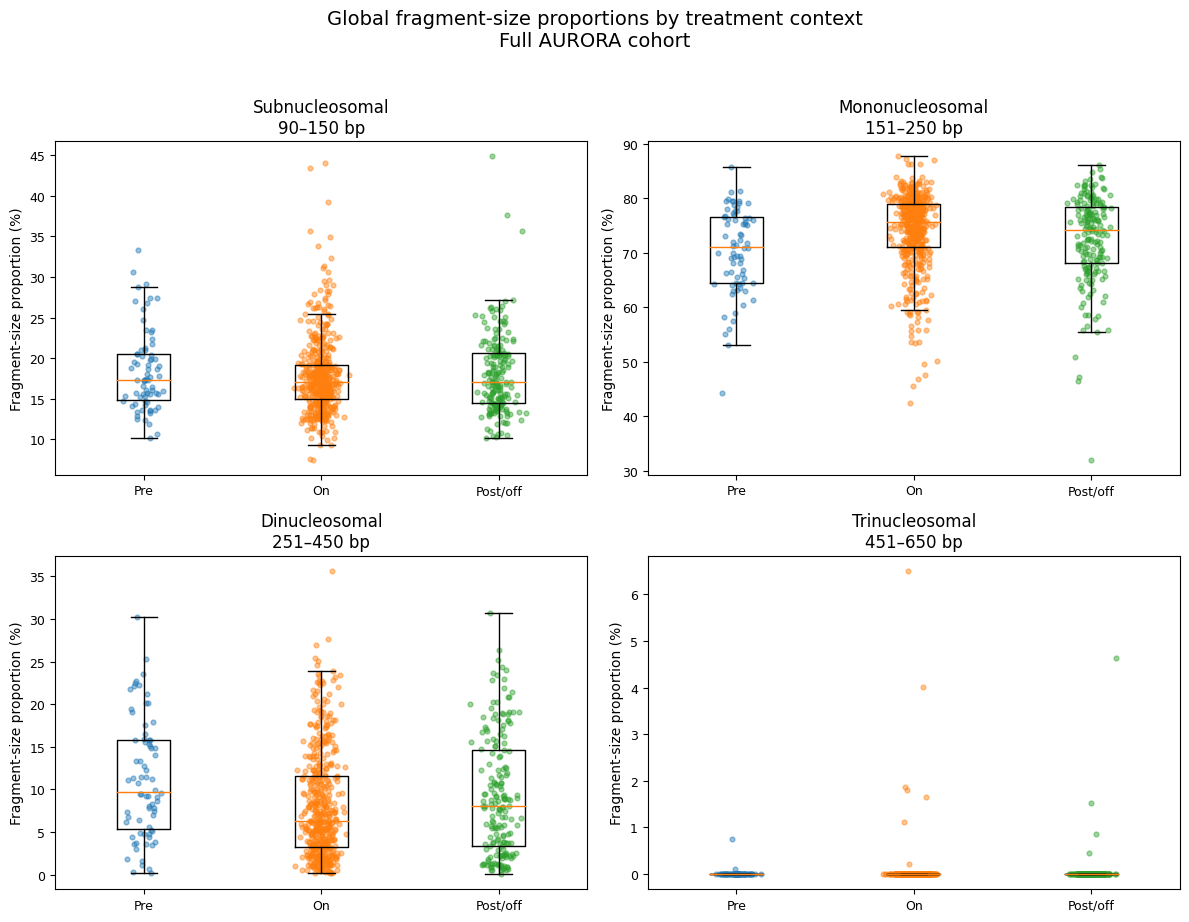

Saved boxplot PNG: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Global_Fragment_analysis/Full_cohort_global_fragmentation_treatment_context_analysis/global_fragmentation_by_treatment_context_boxplots_full_cohort.png
Saved boxplot PDF: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Global_Fragment_analysis/Full_cohort_global_fragmentation_treatment_context_analysis/global_fragmentation_by_treatment_context_boxplots_full_cohort.pdf


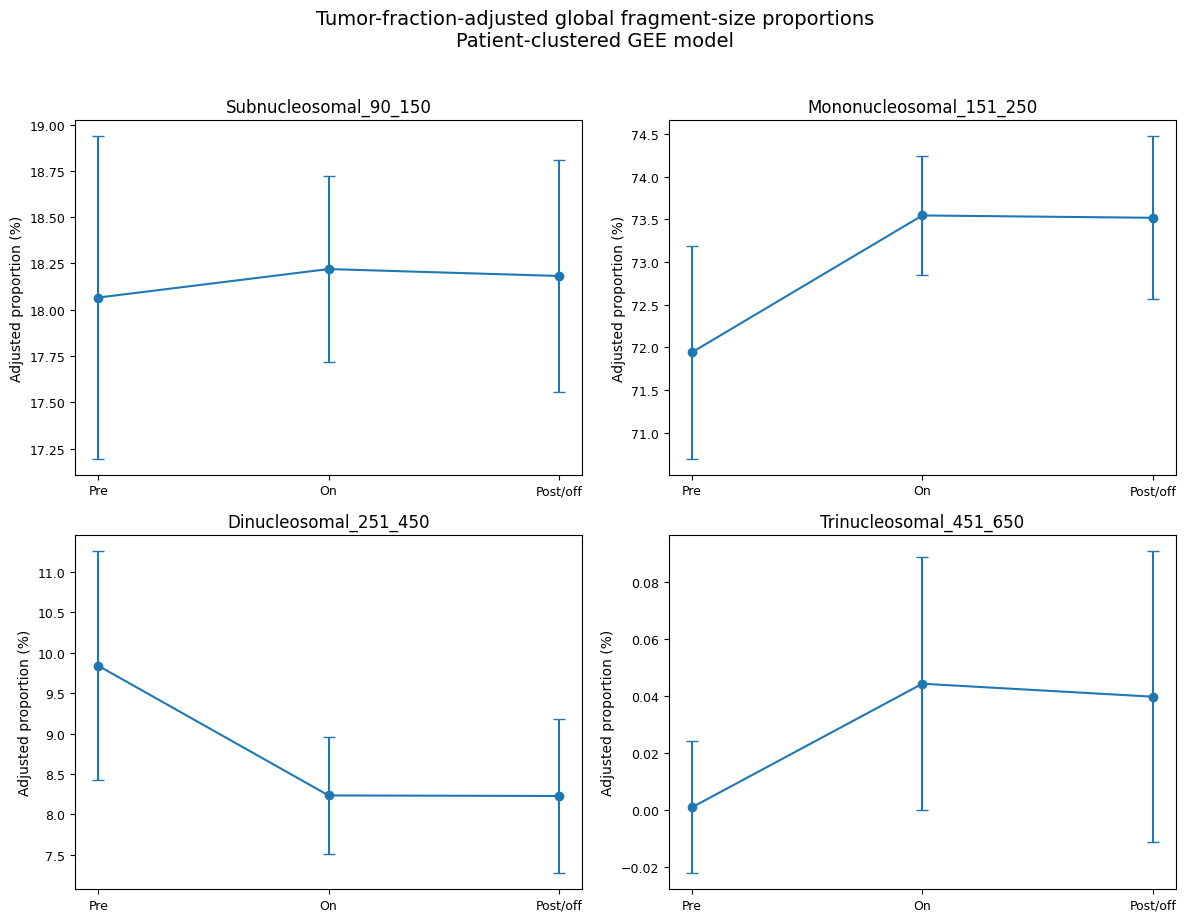

Saved adjusted means PNG: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Global_Fragment_analysis/Full_cohort_global_fragmentation_treatment_context_analysis/gee_adjusted_means_by_treatment_context_full_cohort.png
Saved adjusted means PDF: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Global_Fragment_analysis/Full_cohort_global_fragmentation_treatment_context_analysis/gee_adjusted_means_by_treatment_context_full_cohort.pdf

========== Final interpretation helper ==========

Primary question:
Are global fragment-size proportions different between pre-treatment,
on-treatment, and post/off-treatment blood draws after adjusting for
tumor fraction and repeated sampling?

Primary model:
Fragment-size proportion (%) ~ Treatment context + Tumor fraction (%),
with repeated blood draws clustered by Patient_Identifier using GEE.

Key files to check:
1. gee_global_fragmentation_treatment_context_adjusted_for_TF_patient_clustered_full_cohor

In [4]:
# ============================================================
# Full-cohort global fragmentation analysis by treatment context
# Question:
# Are global fragment-size proportions different between
# pre-treatment, on-treatment, and post/off-treatment blood draws
# after accounting for tumor fraction and repeated sampling?
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
import statsmodels.formula.api as smf
import patsy
import warnings

warnings.filterwarnings("ignore")

# ============================================================
# Input / output paths
# ============================================================

clinical_file = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Clinical_data/All_cases_clinical_CNV_extraction_TSVs/"
    "All_cases_clinical_CNV_extraction.xlsx"
)

fragment_file = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Fragmentation_analysis/Global_Fragment_analysis/Result/"
    "fragment_size_proportions.csv"
)

out_dir = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Fragmentation_analysis/Global_Fragment_analysis"
)

analysis_dir = out_dir / "Full_cohort_global_fragmentation_treatment_context_analysis"
analysis_dir.mkdir(parents=True, exist_ok=True)

print("Output directory:")
print(analysis_dir)

# ============================================================
# Load data
# ============================================================

frag = pd.read_csv(fragment_file)
blood = pd.read_excel(clinical_file, sheet_name="Blood_draws")

print("\n========== Input data ==========")
print(f"Global fragmentation rows: {frag.shape[0]}")
print(f"Global fragmentation columns: {frag.shape[1]}")
print(f"Blood_draws rows: {blood.shape[0]}")
print(f"Blood_draws columns: {blood.shape[1]}")

# ============================================================
# Required columns
# ============================================================

sample_col = "Sample"
barcode_col = "Barcode"
patient_col = "Patient_Identifier"
context_col = "Treatment_context_at_draw"

required_frag_cols = [sample_col]
required_blood_cols = [barcode_col, patient_col, context_col]

missing_frag = [c for c in required_frag_cols if c not in frag.columns]
missing_blood = [c for c in required_blood_cols if c not in blood.columns]

if missing_frag:
    raise ValueError(f"Missing columns in fragmentation file: {missing_frag}")

if missing_blood:
    raise ValueError(f"Missing columns in Blood_draws sheet: {missing_blood}")

# Fragmentation feature columns
fragment_features = [
    "Subnucleosomal_90_150",
    "Mononucleosomal_151_250",
    "Dinucleosomal_251_450",
    "Trinucleosomal_451_650"
]

missing_features = [c for c in fragment_features if c not in frag.columns]

if missing_features:
    raise ValueError(f"Missing fragmentation feature columns: {missing_features}")

# Tumor fraction column
tf_candidates = [
    "Tumor_Fraction_percent_from_CNV_annotation",
    "Tumor_Fraction_percent",
    "Tumor_Fraction"
]

tf_col = None
for c in tf_candidates:
    if c in blood.columns:
        tf_col = c
        break

if tf_col is None:
    raise ValueError(
        "No tumor fraction column found. Checked: "
        + ", ".join(tf_candidates)
    )

print(f"\nTumor fraction column used: {tf_col}")

# ============================================================
# Clean identifiers
# ============================================================

def clean_id(x):
    if pd.isna(x):
        return pd.NA
    x = str(x).strip()
    if x in ["", "NA", "N/A", "nan", "NaN", "None", "Missing"]:
        return pd.NA
    return x

frag[sample_col] = frag[sample_col].apply(clean_id)
blood[barcode_col] = blood[barcode_col].apply(clean_id)
blood[patient_col] = blood[patient_col].apply(clean_id)

# ============================================================
# Merge global fragmentation with blood draw treatment annotation
# ============================================================

merged = frag.merge(
    blood,
    left_on=sample_col,
    right_on=barcode_col,
    how="left",
    indicator=True
)

print("\n========== Merge summary ==========")
print(merged["_merge"].value_counts(dropna=False))

n_total_frag = frag.shape[0]
n_matched = (merged["_merge"] == "both").sum()
n_unmatched = (merged["_merge"] != "both").sum()

print(f"\nFragmentation samples: {n_total_frag}")
print(f"Matched to Blood_draws by Sample = Barcode: {n_matched}")
print(f"Unmatched samples: {n_unmatched}")

# Save unmatched, if any
unmatched_file = analysis_dir / "unmatched_fragmentation_samples.csv"
merged[merged["_merge"] != "both"].to_csv(unmatched_file, index=False)

# ============================================================
# Treatment context classification
# ============================================================

def classify_treatment_context(x):
    """
    Convert detailed treatment-context labels into 3 primary groups.

    Primary groups:
    1. Pre-treatment
    2. On-treatment
    3. Post-treatment/off-treatment

    Excluded:
    - No clinical blood draw date or patient_id mapping
    - No matched treatment context
    - missing/unknown context
    """

    if pd.isna(x):
        return pd.NA

    s = str(x).strip().lower()

    if s in ["pre-treatment", "pretreatment", "pre treatment"]:
        return "Pre-treatment"

    if s in ["on-treatment", "on treatment", "ontreatment"]:
        return "On-treatment"

    if s in ["post-treatment", "post treatment", "posttreatment"]:
        return "Post-treatment/off-treatment"

    if s in [
        "between-treatment-lines",
        "between treatment lines",
        "between-treatment",
        "between treatment"
    ]:
        return "Post-treatment/off-treatment"

    return pd.NA


merged["Treatment_context_3group"] = merged[context_col].apply(classify_treatment_context)

# Convert numeric columns
merged[tf_col] = pd.to_numeric(merged[tf_col], errors="coerce")

# If tumor fraction is decimal, convert to percentage
if merged[tf_col].dropna().quantile(0.99) <= 1.5:
    merged["Tumor_Fraction_percent"] = merged[tf_col] * 100
else:
    merged["Tumor_Fraction_percent"] = merged[tf_col]

for col in fragment_features:
    merged[col] = pd.to_numeric(merged[col], errors="coerce")

# Convert fragment proportions to percentage for plotting/modeling
# If already percentage, leave unchanged
for col in fragment_features:
    if merged[col].dropna().quantile(0.99) <= 1.5:
        merged[col + "_percent"] = merged[col] * 100
    else:
        merged[col + "_percent"] = merged[col]

fragment_features_percent = [c + "_percent" for c in fragment_features]

# ============================================================
# Print treatment-context counts before exclusion
# ============================================================

print("\n========== Original Treatment_context_at_draw counts ==========")
print(
    merged[context_col]
    .fillna("Missing")
    .value_counts(dropna=False)
    .to_string()
)

print("\n========== Final 3-group treatment context counts ==========")
print(
    merged["Treatment_context_3group"]
    .fillna("Excluded/unknown")
    .value_counts(dropna=False)
    .to_string()
)

# ============================================================
# Define sample-level exclusions for primary analysis
# ============================================================

context_excluded = merged[merged["Treatment_context_3group"].isna()].copy()
context_included = merged[merged["Treatment_context_3group"].notna()].copy()

# Add reason
context_excluded["Exclusion_reason"] = context_excluded[context_col].fillna("Missing treatment context")

# Excluded samples file
excluded_samples_file = analysis_dir / "excluded_samples_missing_treatment_context.csv"

excluded_cols = [
    sample_col,
    barcode_col,
    patient_col,
    context_col,
    "Exclusion_reason"
]

available_excluded_cols = [c for c in excluded_cols if c in context_excluded.columns]

context_excluded[available_excluded_cols].to_csv(
    excluded_samples_file,
    index=False
)

# ============================================================
# Identify fully excluded cases
# A case is fully excluded if all its blood draws are excluded
# from the treatment-context analysis.
# ============================================================

case_context_summary = (
    merged
    .groupby(patient_col, dropna=False)
    .agg(
        total_blood_draws=(sample_col, "count"),
        usable_context_blood_draws=("Treatment_context_3group", lambda x: x.notna().sum()),
        excluded_context_blood_draws=("Treatment_context_3group", lambda x: x.isna().sum())
    )
    .reset_index()
)

fully_excluded_cases = case_context_summary[
    (case_context_summary[patient_col].notna()) &
    (case_context_summary["usable_context_blood_draws"] == 0)
].copy()

fully_excluded_case_ids = fully_excluded_cases[patient_col].tolist()

excluded_cases_file = analysis_dir / "fully_excluded_cases_missing_treatment_context.csv"
fully_excluded_cases.to_csv(excluded_cases_file, index=False)

# ============================================================
# Print inclusion/exclusion summary
# ============================================================

print("\n========== Primary treatment-context analysis inclusion/exclusion ==========")

print(f"Total blood draws with global fragmentation: {merged.shape[0]}")
print(f"Included blood draws with assignable treatment context: {context_included.shape[0]}")
print(f"Excluded blood draws with ambiguous/missing treatment context: {context_excluded.shape[0]}")

print(f"\nTotal patients/cases in merged data: {merged[patient_col].nunique(dropna=True)}")
print(f"Patients/cases retained with >=1 usable treatment-context blood draw: {context_included[patient_col].nunique(dropna=True)}")
print(f"Fully excluded patients/cases: {len(fully_excluded_case_ids)}")

print("\nFully excluded case IDs:")
print(fully_excluded_case_ids)

print("\nExcluded sample IDs and reasons:")
if context_excluded.shape[0] > 0:
    print(
        context_excluded[available_excluded_cols]
        .sort_values([patient_col, sample_col])
        .to_string(index=False)
    )
else:
    print("None")

print(f"\nSaved excluded samples: {excluded_samples_file}")
print(f"Saved fully excluded cases: {excluded_cases_file}")

# ============================================================
# Save merged table before model filtering
# ============================================================

merged_file = analysis_dir / "merged_global_fragmentation_treatment_context_full_cohort.csv"
merged.to_csv(merged_file, index=False)

print(f"\nSaved merged table: {merged_file}")

# ============================================================
# Prepare analysis-ready dataset
# Exclude rows missing:
# - treatment context
# - patient ID
# - tumor fraction
# - fragmentation values
# ============================================================

analysis_cols = [
    sample_col,
    barcode_col,
    patient_col,
    "Treatment_context_3group",
    "Tumor_Fraction_percent"
] + fragment_features_percent

optional_cols = [
    "draw_num",
    "patient_id",
    "Active_treatment_at_draw",
    "Most_recent_treatment_before_draw",
    "Next_treatment_after_draw",
    "Treatment_line_at_draw",
    "line_num_context"
]

analysis_cols += [c for c in optional_cols if c in merged.columns]

analysis_df = merged[analysis_cols].copy()

before_model_filter = analysis_df.shape[0]

analysis_df = analysis_df.dropna(
    subset=[
        patient_col,
        "Treatment_context_3group",
        "Tumor_Fraction_percent"
    ] + fragment_features_percent
).copy()

after_model_filter = analysis_df.shape[0]

print("\n========== Model-ready dataset ==========")
print(f"Rows before model filtering: {before_model_filter}")
print(f"Rows after model filtering: {after_model_filter}")
print(f"Rows removed due to missing patient/context/TF/fragmentation: {before_model_filter - after_model_filter}")
print(f"Model-ready patients: {analysis_df[patient_col].nunique()}")

print("\nModel-ready treatment context counts:")
print(
    analysis_df["Treatment_context_3group"]
    .value_counts()
    .reindex(["Pre-treatment", "On-treatment", "Post-treatment/off-treatment"])
    .to_string()
)

# Set categorical order
context_order = [
    "Pre-treatment",
    "On-treatment",
    "Post-treatment/off-treatment"
]

analysis_df["Treatment_context_3group"] = pd.Categorical(
    analysis_df["Treatment_context_3group"],
    categories=context_order,
    ordered=True
)

analysis_ready_file = analysis_dir / "analysis_ready_global_fragmentation_treatment_context_full_cohort.csv"
analysis_df.to_csv(analysis_ready_file, index=False)

print(f"\nSaved analysis-ready table: {analysis_ready_file}")

# ============================================================
# Summary statistics by treatment context
# ============================================================

summary_rows = []

for feature in fragment_features_percent:
    for ctx, g in analysis_df.groupby("Treatment_context_3group", observed=True):
        summary_rows.append({
            "Feature": feature.replace("_percent", ""),
            "Treatment_context": ctx,
            "n_samples": g.shape[0],
            "n_patients": g[patient_col].nunique(),
            "mean_percent": g[feature].mean(),
            "sd_percent": g[feature].std(),
            "median_percent": g[feature].median(),
            "q1_percent": g[feature].quantile(0.25),
            "q3_percent": g[feature].quantile(0.75)
        })

summary_df = pd.DataFrame(summary_rows)

summary_file = analysis_dir / "global_fragmentation_summary_by_treatment_context_full_cohort.csv"
summary_df.to_csv(summary_file, index=False)

print(f"\nSaved summary by treatment context: {summary_file}")

# ============================================================
# Kruskal-Wallis unadjusted group comparison
# This does NOT account for TF or repeated sampling.
# It is included only as descriptive/unadjusted analysis.
# ============================================================

kruskal_rows = []

for feature in fragment_features_percent:
    groups = [
        analysis_df.loc[
            analysis_df["Treatment_context_3group"] == ctx,
            feature
        ].dropna().values
        for ctx in context_order
    ]

    if all(len(g) > 0 for g in groups):
        stat, pval = stats.kruskal(*groups)
    else:
        stat, pval = np.nan, np.nan

    kruskal_rows.append({
        "Feature": feature.replace("_percent", ""),
        "Kruskal_statistic": stat,
        "p_value": pval
    })

kruskal_df = pd.DataFrame(kruskal_rows)

mask = kruskal_df["p_value"].notna()
kruskal_df.loc[mask, "BH_q_value"] = multipletests(
    kruskal_df.loc[mask, "p_value"],
    method="fdr_bh"
)[1]

kruskal_file = analysis_dir / "kruskal_global_fragmentation_by_treatment_context_full_cohort.csv"
kruskal_df.to_csv(kruskal_file, index=False)

print(f"Saved Kruskal-Wallis results: {kruskal_file}")

# ============================================================
# Patient-clustered GEE model adjusted for tumor fraction and clustered by patient
# Model:
# Fragment-size proportion ~ Treatment context + Tumor fraction
# repeated sampling handled by patient-clustered GEE
# ============================================================

gee_rows = []
pairwise_rows = []
adjusted_mean_rows = []

for feature in fragment_features_percent:

    print(f"\nRunning GEE model for: {feature}")

    model_df = analysis_df[
        [
            patient_col,
            "Treatment_context_3group",
            "Tumor_Fraction_percent",
            feature
        ]
    ].dropna().copy()

    # Rename feature to a simple outcome name for formula
    model_df = model_df.rename(columns={feature: "Fragment_percent"})

    # Make sure categories are preserved
    model_df["Treatment_context_3group"] = pd.Categorical(
        model_df["Treatment_context_3group"],
        categories=context_order,
        ordered=True
    )

    formula = (
        'Fragment_percent ~ '
        'C(Treatment_context_3group, Treatment(reference="Pre-treatment")) '
        '+ Tumor_Fraction_percent'
    )

    try:
        gee_model = smf.gee(
            formula=formula,
            groups=model_df[patient_col],
            data=model_df,
            family=sm.families.Gaussian(),
            cov_struct=sm.cov_struct.Exchangeable()
        )

        gee_result = gee_model.fit()

        params = gee_result.params
        pvals = gee_result.pvalues
        conf = gee_result.conf_int()

        # Overall treatment-context Wald test
        ctx_param_names = [
            p for p in params.index
            if "Treatment_context_3group" in p
        ]

        if len(ctx_param_names) > 0:
            R = np.zeros((len(ctx_param_names), len(params)))
            param_names = list(params.index)

            for i, pname in enumerate(ctx_param_names):
                R[i, param_names.index(pname)] = 1

            wald_res = gee_result.wald_test(R)
            context_global_p = float(wald_res.pvalue)
        else:
            context_global_p = np.nan

        # Save coefficients
        for term in params.index:
            gee_rows.append({
                "Feature": feature.replace("_percent", ""),
                "Model": "GEE_patient_clustered_adjusted_for_TF",
                "Term": term,
                "Coefficient": params[term],
                "CI_lower": conf.loc[term, 0],
                "CI_upper": conf.loc[term, 1],
                "p_value": pvals[term],
                "Treatment_context_global_p": context_global_p,
                "n_samples": model_df.shape[0],
                "n_patients": model_df[patient_col].nunique()
            })

        # Adjusted means at mean tumor fraction
        mean_tf = model_df["Tumor_Fraction_percent"].mean()
        design_info = gee_result.model.data.design_info
        cov = gee_result.cov_params()

        new_data = pd.DataFrame({
            "Treatment_context_3group": pd.Categorical(
                context_order,
                categories=context_order,
                ordered=True
            ),
            "Tumor_Fraction_percent": [mean_tf] * len(context_order)
        })

        X_new = patsy.build_design_matrices(
            [design_info],
            new_data,
            return_type="dataframe"
        )[0]

        pred = np.asarray(X_new @ params)
        pred_var = np.diag(np.asarray(X_new @ cov @ X_new.T))
        pred_se = np.sqrt(pred_var)

        for ctx, est, se in zip(context_order, pred, pred_se):
            adjusted_mean_rows.append({
                "Feature": feature.replace("_percent", ""),
                "Treatment_context": ctx,
                "Adjusted_mean_percent": est,
                "SE": se,
                "CI_lower": est - 1.96 * se,
                "CI_upper": est + 1.96 * se,
                "Mean_TF_used_for_adjustment": mean_tf,
                "n_samples": model_df.shape[0],
                "n_patients": model_df[patient_col].nunique()
            })

        # Pairwise adjusted contrasts
        pairs = [
            ("On-treatment", "Pre-treatment"),
            ("Post-treatment/off-treatment", "Pre-treatment"),
            ("Post-treatment/off-treatment", "On-treatment")
        ]

        X_lookup = {
            ctx: np.asarray(X_new.loc[i])
            for i, ctx in enumerate(context_order)
        }

        for ctx_a, ctx_b in pairs:
            L = X_lookup[ctx_a] - X_lookup[ctx_b]
            diff = float(L @ params)
            se = float(np.sqrt(L @ cov @ L.T))
            z = diff / se if se > 0 else np.nan
            p = 2 * (1 - stats.norm.cdf(abs(z))) if not pd.isna(z) else np.nan

            pairwise_rows.append({
                "Feature": feature.replace("_percent", ""),
                "Contrast": f"{ctx_a} minus {ctx_b}",
                "Difference_percent_points": diff,
                "SE": se,
                "z": z,
                "p_value": p,
                "CI_lower": diff - 1.96 * se,
                "CI_upper": diff + 1.96 * se,
                "Mean_TF_used_for_adjustment": mean_tf
            })

    except Exception as e:
        print(f"Model failed for {feature}: {e}")

        gee_rows.append({
            "Feature": feature.replace("_percent", ""),
            "Model": "GEE_patient_clustered_adjusted_for_TF",
            "Term": "MODEL_FAILED",
            "Coefficient": np.nan,
            "CI_lower": np.nan,
            "CI_upper": np.nan,
            "p_value": np.nan,
            "Treatment_context_global_p": np.nan,
            "n_samples": model_df.shape[0],
            "n_patients": model_df[patient_col].nunique(),
            "Error": str(e)
        })

gee_df = pd.DataFrame(gee_rows)
pairwise_df = pd.DataFrame(pairwise_rows)
adjusted_means_df = pd.DataFrame(adjusted_mean_rows)

# BH adjustment for global treatment-context p-value across features
global_p = (
    gee_df[["Feature", "Treatment_context_global_p"]]
    .drop_duplicates()
    .dropna()
    .copy()
)

if global_p.shape[0] > 0:
    global_p["Treatment_context_global_BH_q"] = multipletests(
        global_p["Treatment_context_global_p"],
        method="fdr_bh"
    )[1]

    gee_df = gee_df.merge(
        global_p,
        on=["Feature", "Treatment_context_global_p"],
        how="left"
    )

# BH adjustment for coefficient p-values
coef_mask = gee_df["p_value"].notna() & (gee_df["Term"] != "Intercept")
if coef_mask.sum() > 0:
    gee_df.loc[coef_mask, "Coefficient_BH_q"] = multipletests(
        gee_df.loc[coef_mask, "p_value"],
        method="fdr_bh"
    )[1]

# BH adjustment for pairwise p-values
if pairwise_df.shape[0] > 0:
    mask = pairwise_df["p_value"].notna()
    pairwise_df.loc[mask, "BH_q_value"] = multipletests(
        pairwise_df.loc[mask, "p_value"],
        method="fdr_bh"
    )[1]

gee_file = analysis_dir / "gee_global_fragmentation_treatment_context_adjusted_for_TF_patient_clustered_full_cohort.csv"
pairwise_file = analysis_dir / "gee_pairwise_treatment_context_contrasts_global_fragmentation_full_cohort.csv"
adjusted_means_file = analysis_dir / "gee_adjusted_means_by_treatment_context_global_fragmentation_full_cohort.csv"

gee_df.to_csv(gee_file, index=False)
pairwise_df.to_csv(pairwise_file, index=False)
adjusted_means_df.to_csv(adjusted_means_file, index=False)

print(f"\nSaved GEE model results: {gee_file}")
print(f"Saved pairwise adjusted contrasts: {pairwise_file}")
print(f"Saved adjusted means: {adjusted_means_file}")

# ============================================================
# Plot 1: Boxplots by treatment context
# ============================================================

feature_labels = {
    "Subnucleosomal_90_150_percent": "Subnucleosomal\n90–150 bp",
    "Mononucleosomal_151_250_percent": "Mononucleosomal\n151–250 bp",
    "Dinucleosomal_251_450_percent": "Dinucleosomal\n251–450 bp",
    "Trinucleosomal_451_650_percent": "Trinucleosomal\n451–650 bp"
}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.reshape(-1)

for ax, feature in zip(axes, fragment_features_percent):

    data = [
        analysis_df.loc[
            analysis_df["Treatment_context_3group"] == ctx,
            feature
        ].dropna()
        for ctx in context_order
    ]

    ax.boxplot(
        data,
        labels=["Pre", "On", "Post/off"],
        showfliers=False
    )

    # Add jittered points
    for i, vals in enumerate(data, start=1):
        x = np.random.normal(i, 0.05, size=len(vals))
        ax.scatter(x, vals, s=12, alpha=0.45)

    ax.set_title(feature_labels.get(feature, feature), fontsize=12)
    ax.set_ylabel("Fragment-size proportion (%)", fontsize=10)
    ax.tick_params(axis="both", labelsize=9)

plt.suptitle(
    "Global fragment-size proportions by treatment context\nFull AURORA cohort",
    fontsize=14,
    y=1.02
)

plt.tight_layout()

box_png = analysis_dir / "global_fragmentation_by_treatment_context_boxplots_full_cohort.png"
box_pdf = analysis_dir / "global_fragmentation_by_treatment_context_boxplots_full_cohort.pdf"

plt.savefig(box_png, dpi=300, bbox_inches="tight", facecolor="white")
plt.savefig(box_pdf, bbox_inches="tight", facecolor="white")
plt.show()

print(f"Saved boxplot PNG: {box_png}")
print(f"Saved boxplot PDF: {box_pdf}")

# ============================================================
# Plot 2: GEE adjusted means by treatment context after adjusting for TFx
# Are fragment-size proportions different across treatment contexts after adjusting for TFx?
# ============================================================

if adjusted_means_df.shape[0] > 0:

    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    axes = axes.reshape(-1)

    for ax, feature in zip(axes, [f.replace("_percent", "") for f in fragment_features_percent]):

        g = adjusted_means_df[
            adjusted_means_df["Feature"] == feature
        ].copy()

        g["Treatment_context"] = pd.Categorical(
            g["Treatment_context"],
            categories=context_order,
            ordered=True
        )
        g = g.sort_values("Treatment_context")

        x = np.arange(g.shape[0])
        y = g["Adjusted_mean_percent"].values
        yerr_lower = y - g["CI_lower"].values
        yerr_upper = g["CI_upper"].values - y

        ax.errorbar(
            x,
            y,
            yerr=[yerr_lower, yerr_upper],
            marker="o",
            linestyle="-",
            capsize=4
        )

        ax.set_xticks(x)
        ax.set_xticklabels(["Pre", "On", "Post/off"])
        ax.set_title(feature, fontsize=12)
        ax.set_ylabel("Adjusted proportion (%)", fontsize=10)
        ax.tick_params(axis="both", labelsize=9)

    plt.suptitle(
        "Tumor-fraction-adjusted global fragment-size proportions\n"
        "Patient-clustered GEE model",
        fontsize=14,
        y=1.02
    )

    plt.tight_layout()

    adj_png = analysis_dir / "gee_adjusted_means_by_treatment_context_full_cohort.png"
    adj_pdf = analysis_dir / "gee_adjusted_means_by_treatment_context_full_cohort.pdf"

    plt.savefig(adj_png, dpi=300, bbox_inches="tight", facecolor="white")
    plt.savefig(adj_pdf, bbox_inches="tight", facecolor="white")
    plt.show()

    print(f"Saved adjusted means PNG: {adj_png}")
    print(f"Saved adjusted means PDF: {adj_pdf}")

# ============================================================
# Final printed summary
# ============================================================

print("\n========== Final interpretation helper ==========")

print(
    """
Primary question:
Are global fragment-size proportions different between pre-treatment,
on-treatment, and post/off-treatment blood draws after adjusting for
tumor fraction and repeated sampling?

Primary model:
Fragment-size proportion (%) ~ Treatment context + Tumor fraction (%),
with repeated blood draws clustered by Patient_Identifier using GEE.

Key files to check:
1. gee_global_fragmentation_treatment_context_adjusted_for_TF_patient_clustered_full_cohort.csv
   - Main adjusted model results.
   - Look at Treatment_context_global_p and Treatment_context_global_BH_q.

2. gee_pairwise_treatment_context_contrasts_global_fragmentation_full_cohort.csv
   - Pairwise adjusted comparisons:
     On vs Pre, Post/off vs Pre, Post/off vs On.

3. gee_adjusted_means_by_treatment_context_global_fragmentation_full_cohort.csv
   - Adjusted mean fragment proportions by treatment context.

4. excluded_samples_missing_treatment_context.csv
   - Samples excluded from treatment-context analysis.

5. fully_excluded_cases_missing_treatment_context.csv
   - Patients/cases fully excluded because none of their blood draws had
     assignable treatment context.
"""
)


========== Tumor fraction coefficient plot ==========
Saved tumor fraction coefficient table: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Global_Fragment_analysis/Full_cohort_global_fragmentation_treatment_context_analysis/gee_tumor_fraction_coefficients_global_fragmentation_full_cohort.csv


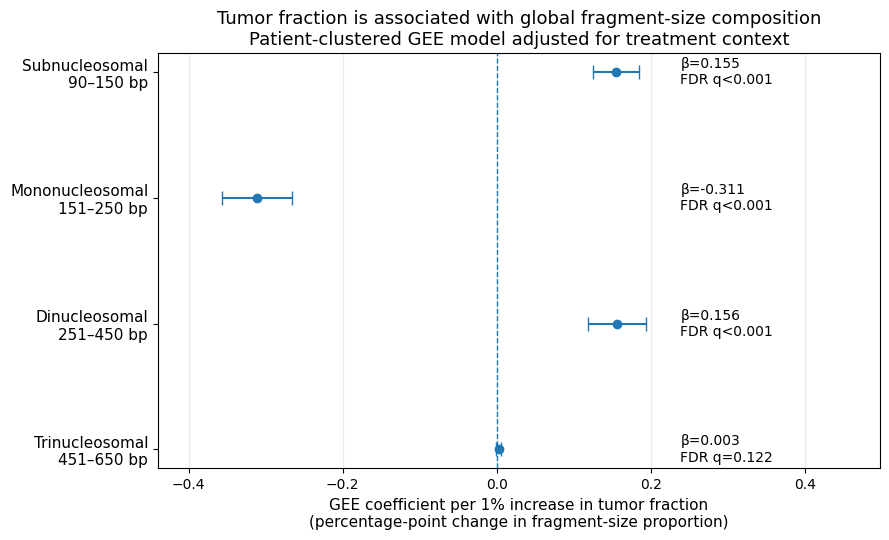

Saved tumor fraction coefficient PNG: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Global_Fragment_analysis/Full_cohort_global_fragmentation_treatment_context_analysis/gee_tumor_fraction_coefficients_global_fragmentation_full_cohort.png
Saved tumor fraction coefficient PDF: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Global_Fragment_analysis/Full_cohort_global_fragmentation_treatment_context_analysis/gee_tumor_fraction_coefficients_global_fragmentation_full_cohort.pdf

========== Tumor fraction effect summary ==========
Subnucleosomal 90–150 bp: tumor fraction increases this fragment class (β=0.155 percentage points per 1% TF, 95% CI 0.126 to 0.185, p=1.8e-24, FDR q=1.1e-23).
Mononucleosomal 151–250 bp: tumor fraction decreases this fragment class (β=-0.311 percentage points per 1% TF, 95% CI -0.357 to -0.265, p=3.3e-40, FDR q=4.0e-39).
Dinucleosomal 251–450 bp: tumor fraction increases this fragment class (β=0.156 percenta

In [5]:
# ============================================================
# Plot 3: Tumor fraction effect on global fragment-size proportions after adjusting for treatment context
# Is TFx associated with fragment-size proportions after adjusting for treatment context?
# From the same patient-clustered GEE model
#
# Interpretation:
# Coefficient = percentage-point change in fragment-size proportion
# per 1% increase in ichorCNA tumor fraction
# ============================================================

print("\n========== Tumor fraction coefficient plot ==========")


analysis_dir = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Fragmentation_analysis/Global_Fragment_analysis/"
    "Full_cohort_global_fragmentation_treatment_context_analysis")

gee_file = analysis_dir / "gee_global_fragmentation_treatment_context_adjusted_for_TF_patient_clustered_full_cohort.csv"
gee_df = pd.read_csv(gee_file)

# Extract tumor fraction term only
tf_effect_df = gee_df[
    gee_df["Term"] == "Tumor_Fraction_percent"
].copy()

if tf_effect_df.empty:
    raise ValueError("No Tumor_Fraction_percent term found in GEE results.")

# Clean feature labels for plotting
feature_label_map = {
    "Subnucleosomal_90_150": "Subnucleosomal\n90–150 bp",
    "Mononucleosomal_151_250": "Mononucleosomal\n151–250 bp",
    "Dinucleosomal_251_450": "Dinucleosomal\n251–450 bp",
    "Trinucleosomal_451_650": "Trinucleosomal\n451–650 bp"
}

tf_effect_df["Feature_label"] = tf_effect_df["Feature"].map(feature_label_map)

# Preserve desired order
feature_order = [
    "Subnucleosomal_90_150",
    "Mononucleosomal_151_250",
    "Dinucleosomal_251_450",
    "Trinucleosomal_451_650"
]

tf_effect_df["Feature"] = pd.Categorical(
    tf_effect_df["Feature"],
    categories=feature_order,
    ordered=True
)

tf_effect_df = tf_effect_df.sort_values("Feature").reset_index(drop=True)

# Add significance labels
def format_p(x):
    if pd.isna(x):
        return "NA"
    if x < 0.001:
        return f"{x:.1e}"
    return f"{x:.3f}"

def significance_label(q):
    if pd.isna(q):
        return "q=NA"
    if q < 0.001:
        return "FDR q<0.001"
    if q < 0.01:
        return "FDR q<0.01"
    if q < 0.05:
        return "FDR q<0.05"
    if q < 0.10:
        return "FDR q<0.10"
    return f"FDR q={q:.3f}"

# Use Coefficient_BH_q if available
if "Coefficient_BH_q" in tf_effect_df.columns:
    tf_effect_df["TF_q_label"] = tf_effect_df["Coefficient_BH_q"].apply(significance_label)
else:
    tf_effect_df["TF_q_label"] = tf_effect_df["p_value"].apply(lambda x: f"p={format_p(x)}")

tf_effect_df["Plot_label"] = (
    "β=" + tf_effect_df["Coefficient"].round(3).astype(str)
    + "\n" + tf_effect_df["TF_q_label"]
)

# Save tumor-fraction effect table
tf_effect_file = analysis_dir / "gee_tumor_fraction_coefficients_global_fragmentation_full_cohort.csv"
tf_effect_df.to_csv(tf_effect_file, index=False)

print(f"Saved tumor fraction coefficient table: {tf_effect_file}")

# ============================================================
# Forest/coefficient plot
# ============================================================

fig, ax = plt.subplots(figsize=(9, 5.5))

y_pos = np.arange(tf_effect_df.shape[0])

coef = tf_effect_df["Coefficient"].values
ci_low = tf_effect_df["CI_lower"].values
ci_high = tf_effect_df["CI_upper"].values

xerr_lower = coef - ci_low
xerr_upper = ci_high - coef

ax.errorbar(
    coef,
    y_pos,
    xerr=[xerr_lower, xerr_upper],
    fmt="o",
    capsize=5,
    markersize=6
)

# Reference line at zero
ax.axvline(0, linestyle="--", linewidth=1)

# Y-axis labels
ax.set_yticks(y_pos)
ax.set_yticklabels(tf_effect_df["Feature_label"], fontsize=11)
ax.invert_yaxis()

# Axis labels and title
ax.set_xlabel(
    "GEE coefficient per 1% increase in tumor fraction\n"
    "(percentage-point change in fragment-size proportion)",
    fontsize=11
)

ax.set_title(
    "Tumor fraction is associated with global fragment-size composition\n"
    "Patient-clustered GEE model adjusted for treatment context",
    fontsize=13
)

# Add coefficient and FDR q-value labels
x_range = max(ci_high) - min(ci_low)
label_x = max(ci_high) + 0.08 * x_range

for i, row in tf_effect_df.iterrows():
    ax.text(
        label_x,
        i,
        row["Plot_label"],
        va="center",
        fontsize=10
    )

# Expand x-limits for labels
ax.set_xlim(
    min(ci_low) - 0.15 * x_range,
    max(ci_high) + 0.55 * x_range
)

ax.tick_params(axis="x", labelsize=10)
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()

tf_coef_png = analysis_dir / "gee_tumor_fraction_coefficients_global_fragmentation_full_cohort.png"
tf_coef_pdf = analysis_dir / "gee_tumor_fraction_coefficients_global_fragmentation_full_cohort.pdf"

plt.savefig(tf_coef_png, dpi=300, bbox_inches="tight", facecolor="white")
plt.savefig(tf_coef_pdf, bbox_inches="tight", facecolor="white")
plt.show()

print(f"Saved tumor fraction coefficient PNG: {tf_coef_png}")
print(f"Saved tumor fraction coefficient PDF: {tf_coef_pdf}")

# ============================================================
# Print interpretation
# ============================================================

print("\n========== Tumor fraction effect summary ==========")

for _, row in tf_effect_df.iterrows():
    feature = row["Feature_label"].replace("\n", " ")
    beta = row["Coefficient"]
    ci1 = row["CI_lower"]
    ci2 = row["CI_upper"]
    p = row["p_value"]
    q = row.get("Coefficient_BH_q", np.nan)

    direction = "increases" if beta > 0 else "decreases"

    print(
        f"{feature}: tumor fraction {direction} this fragment class "
        f"(β={beta:.3f} percentage points per 1% TF, "
        f"95% CI {ci1:.3f} to {ci2:.3f}, "
        f"p={format_p(p)}, "
        f"FDR q={format_p(q)})."
    )